# Machine Learning Laboratory Experiments
## Experiments: SVM, KNN, and Model Evaluation & Hyperparameter Tuning

---

### Objectives Covered:
1. **Experiment 8: Support Vector Machine (SVM)**
   - Implement Linear and Kernel SVM classifiers (`Linear`, `RBF`, `Polynomial`, `Sigmoid`).
   - Compare different kernels on benchmark datasets (Wisconsin Breast Cancer & Non-linear Moons).
   - Visualize decision boundaries and analyze support vectors, margins, and kernel characteristics.
2. **Experiment 9: K-Nearest Neighbors (KNN)**
   - Implement the KNN classifier from foundational principles.
   - Analyze the impact of different values of $K$ ($K=1$ to $K=35$) on bias-variance tradeoff.
   - Evaluate the impact of various distance metrics (`Euclidean`, `Manhattan`, `Minkowski`, `Chebyshev`).
   - Visualize decision boundary geometry differences across metrics.
3. **Experiment 10: Model Evaluation & Hyperparameter Tuning**
   - Evaluate models with comprehensive metrics: **Accuracy, Precision, Recall, F1-Score, ROC-AUC**.
   - Generate and interpret Confusion Matrices and ROC Curves.
   - Perform $K$-Fold Cross-Validation (Stratified 5-Fold and 10-Fold).
   - Compare hyperparameter optimization techniques: **Grid Search (`GridSearchCV`)** vs. **Random Search (`RandomizedSearchCV`)** in terms of accuracy, search time, and convergence.

### Step 1: Library Imports & Visualization Configuration

In [1]:
# Import essential libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

# Scikit-Learn modules
from sklearn.datasets import load_breast_cancer, make_moons
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

# Plot styling configuration
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print("Environment configured successfully!")
print(f"NumPy Version: {np.__version__}")
print(f"Pandas Version: {pd.__version__}")

Environment configured successfully!
NumPy Version: 2.5.3
Pandas Version: 3.0.6


### Step 2: Benchmark Dataset Exploration & Preprocessing

We use the **Breast Cancer Wisconsin (Diagnostic)** benchmark dataset from Scikit-Learn:
- **Samples**: 569 instances
- **Features**: 30 continuous real-valued cellular metrics (e.g., radius, texture, perimeter, area, smoothness, concavity)
- **Target**: Binary classification (0: Malignant, 1: Benign)

> **Preprocessing Requirement**: Both SVM and KNN rely directly on geometric distances in feature space. If features have unequal scales, variables with larger magnitudes dominate the distance calculations. Hence, **Standard Normalization** ($\mu=0, \sigma=1$) via `StandardScaler` is strictly applied.

In [2]:
# Load the Breast Cancer Wisconsin Benchmark Dataset
data = load_breast_cancer()
X = data.data
y = data.target
feature_names = data.feature_names
target_names = data.target_names

df = pd.DataFrame(X, columns=feature_names)
df['target'] = y
df['target_name'] = df['target'].map({0: target_names[0], 1: target_names[1]})

print(f"Dataset Shape: {X.shape[0]} samples, {X.shape[1]} features")
print(f"Classes: {target_names[0]} (0) vs {target_names[1]} (1)")
print(f"Class Distribution:\n{df['target_name'].value_counts()}\n")

# Train-Test Split (80% Train, 20% Test) stratified by class
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Feature Scaling (Fit on Train, Transform on both Train & Test)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

print(f"Training Set: {X_train.shape[0]} samples")
print(f"Testing Set:  {X_test.shape[0]} samples")
print("Data normalized successfully (Train mean ~ 0, std ~ 1).")

Dataset Shape: 569 samples, 30 features
Classes: malignant (0) vs benign (1)
Class Distribution:
target_name
benign       357
malignant    212
Name: count, dtype: int64

Training Set: 455 samples
Testing Set:  114 samples
Data normalized successfully (Train mean ~ 0, std ~ 1).


---
# Experiment 8: Support Vector Machine (SVM)

### Theoretical Foundations
Support Vector Machines aim to construct an optimal hyper-plane:
$$w^T x + b = 0$$
which separates the classes with the maximum geometric margin $\frac{2}{\|w\|}$, while penalizing margin violations with a regularization constant $C$:
$$\min_{w, b, \xi} \frac{1}{2} \|w\|^2 + C \sum_{i=1}^N \xi_i$$

### Kernels: Transforming Non-Linear Data
When data is not linearly separable in the input space, the **Kernel Trick** maps inputs into a higher-dimensional feature space $\Phi(x)$ where linear separation is possible without computing coordinates in that high-dimensional space:
1. **Linear Kernel**:
   $$K(x, x') = x^T x'$$
2. **Polynomial Kernel**:
   $$K(x, x') = (\gamma x^T x' + r)^d$$
3. **Radial Basis Function (RBF / Gaussian)**:
   $$K(x, x') = \exp(-\gamma \|x - x'\|^2)$$
4. **Sigmoid Kernel**:
   $$K(x, x') = \tanh(\gamma x^T x' + r)$$

### 8.1: Training & Evaluating Linear vs. Kernel SVMs

In [3]:
# Experiment 8.1: Comparison of SVM Kernels on Breast Cancer Benchmark Dataset
kernels = ['linear', 'rbf', 'poly', 'sigmoid']
svm_results = []
svm_models = {}

for k in kernels:
    start_time = time.time()
    # Instantiate SVC with probability=True for ROC-AUC computation
    model = SVC(kernel=k, C=1.0, probability=True, random_state=42)
    model.fit(X_train, y_train)
    fit_time = (time.time() - start_time) * 1000 # milliseconds
    
    # Predictions
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)
    y_proba_test = model.predict_proba(X_test)[:, 1]
    
    # Compute Metrics
    train_acc = accuracy_score(y_train, y_pred_train)
    test_acc = accuracy_score(y_test, y_pred_test)
    prec = precision_score(y_test, y_pred_test)
    rec = recall_score(y_test, y_pred_test)
    f1 = f1_score(y_test, y_pred_test)
    auc = roc_auc_score(y_test, y_proba_test)
    n_support = model.support_vectors_.shape[0]
    
    svm_models[k] = model
    svm_results.append({
        'Kernel': k.upper(),
        'Train Accuracy': round(train_acc * 100, 2),
        'Test Accuracy': round(test_acc * 100, 2),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-Score': round(f1, 4),
        'ROC-AUC': round(auc, 4),
        'Support Vectors': n_support,
        'Fit Time (ms)': round(fit_time, 2)
    })

df_svm_results = pd.DataFrame(svm_results)
print("=== SVM KERNEL PERFORMANCE COMPARISON ===")
print(df_svm_results.to_string(index=False))

=== SVM KERNEL PERFORMANCE COMPARISON ===
 Kernel  Train Accuracy  Test Accuracy  Precision  Recall  F1-Score  ROC-AUC  Support Vectors  Fit Time (ms)
 LINEAR           99.12          97.37     0.9859  0.9722    0.9790   0.9964               32           6.11
    RBF           98.24          98.25     0.9861  0.9861    0.9861   0.9950               97           7.50
   POLY           91.65          91.23     0.8780  1.0000    0.9351   0.9954              145           6.65
SIGMOID           95.60          92.98     0.9571  0.9306    0.9437   0.9907               66           6.62


### 8.2: Metric Comparison & Support Vector Density

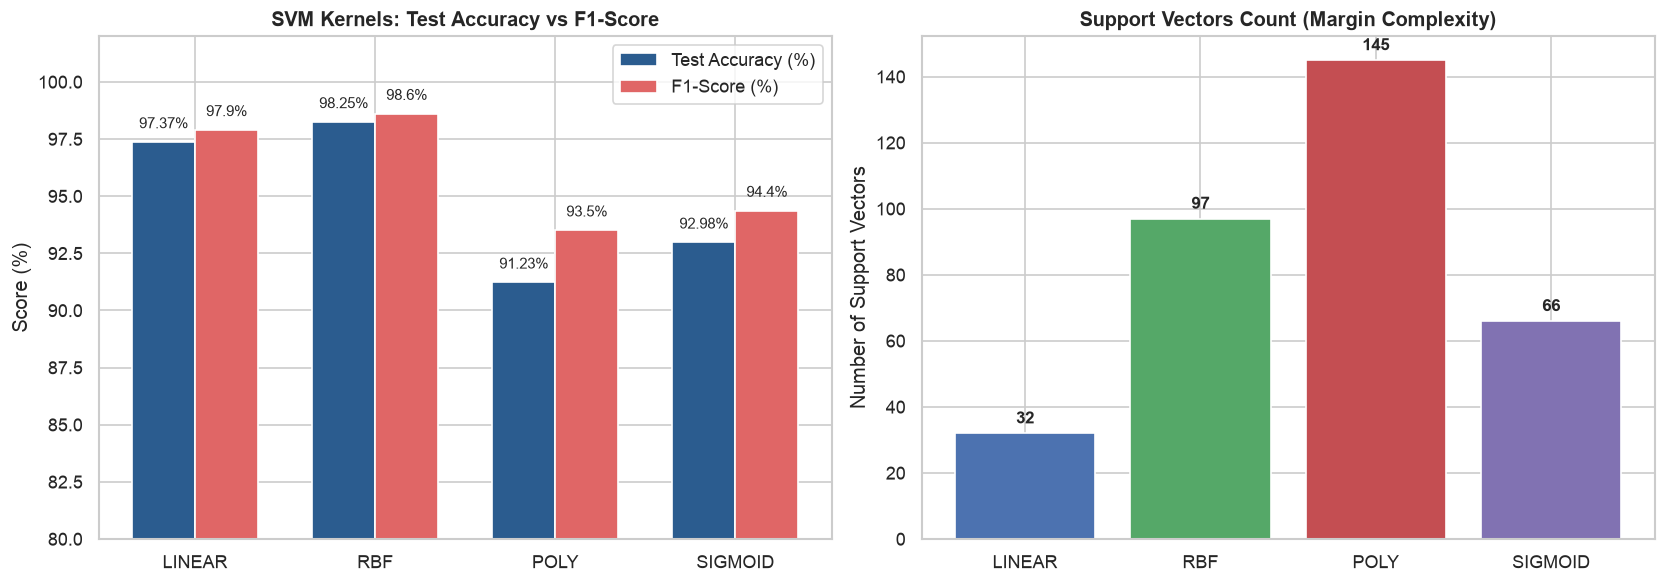

In [4]:
# Experiment 8.2: Visualizing SVM Kernel Performance Metrics
plt.figure(figsize=(14, 5))

# Subplot 1: Accuracy & F1-Score Comparison
plt.subplot(1, 2, 1)
x_indices = np.arange(len(df_svm_results))
bar_width = 0.35

plt.bar(x_indices - bar_width/2, df_svm_results['Test Accuracy'], width=bar_width, label='Test Accuracy (%)', color='#2b5c8f')
plt.bar(x_indices + bar_width/2, df_svm_results['F1-Score'] * 100, width=bar_width, label='F1-Score (%)', color='#e06666')
plt.xticks(x_indices, df_svm_results['Kernel'])
plt.ylabel('Score (%)')
plt.title('SVM Kernels: Test Accuracy vs F1-Score', fontsize=12, fontweight='bold')
plt.ylim(80, 102)
plt.legend()
for i in x_indices:
    plt.text(i - bar_width/2, df_svm_results['Test Accuracy'][i] + 0.6, f"{df_svm_results['Test Accuracy'][i]}%", ha='center', fontsize=9)
    plt.text(i + bar_width/2, df_svm_results['F1-Score'][i]*100 + 0.6, f"{df_svm_results['F1-Score'][i]*100:.1f}%", ha='center', fontsize=9)

# Subplot 2: Number of Support Vectors per Kernel
plt.subplot(1, 2, 2)
palette = ['#4c72b0', '#55a868', '#c44e52', '#8172b2']
bars = plt.bar(df_svm_results['Kernel'], df_svm_results['Support Vectors'], color=palette)
plt.ylabel('Number of Support Vectors')
plt.title('Support Vectors Count (Margin Complexity)', fontsize=12, fontweight='bold')
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 3, f"{int(yval)}", ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

### 8.3: Decision Boundary Visualizations Across Kernels

The plots below contrast how each kernel forms boundaries:
- **Linear**: Strictly separates classes with a flat hyper-plane. High accuracy on cancer data due to high-dimensional separability, but cannot separate interleaving moons.
- **RBF**: Smooth Gaussian contours around non-linear distributions, adapting well to arbitrary complex structures.
- **Polynomial**: Higher-degree polynomial curves capturing curved geometries.
- **Sigmoid**: Behaves like a two-layer perceptron; sensitive to hyperparameters and prone to poor separation when not tuned.

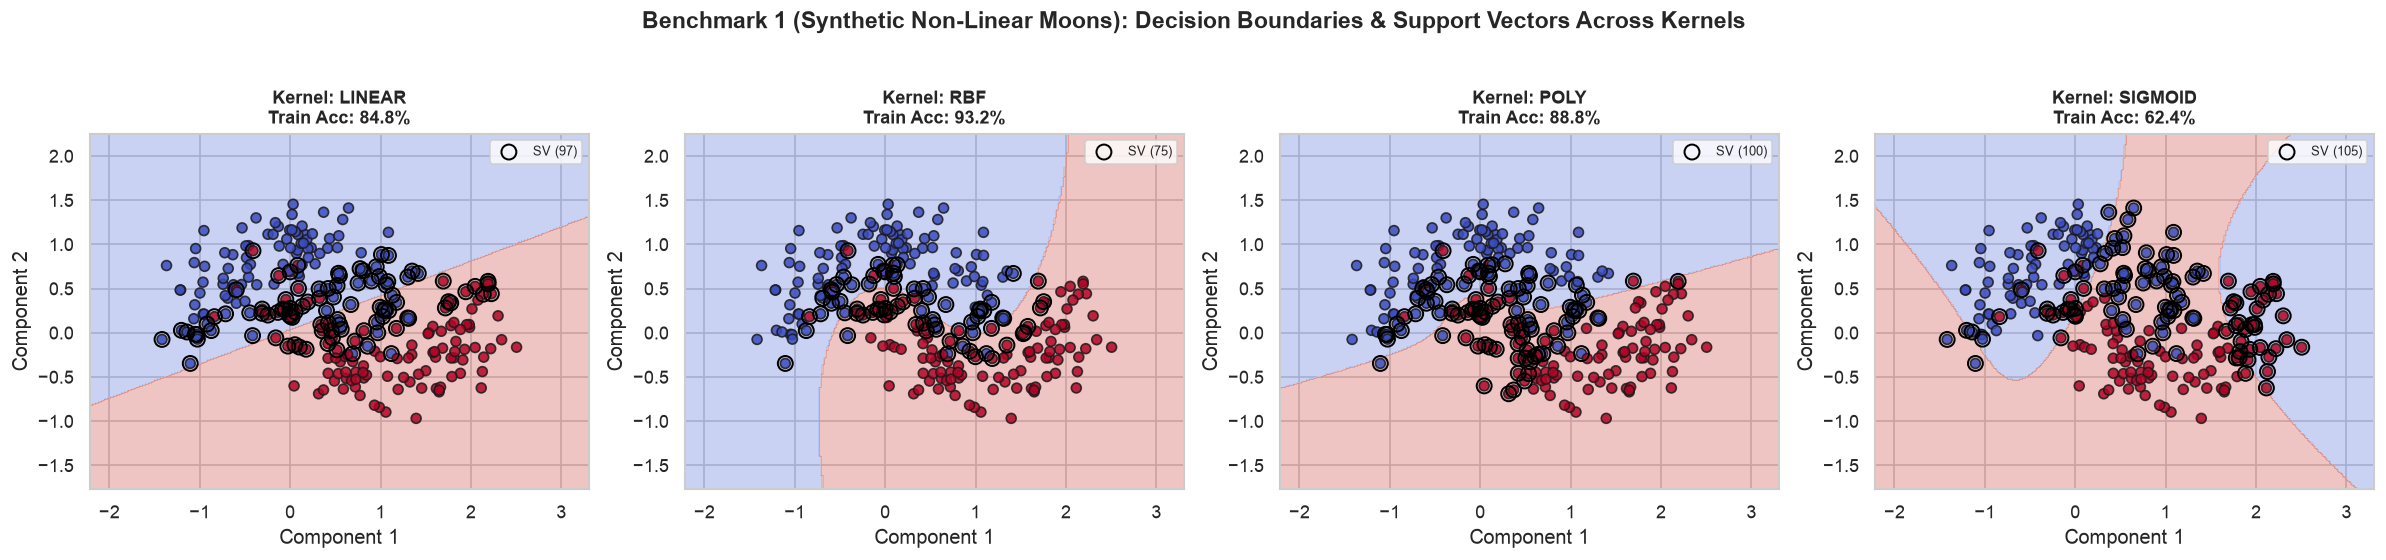

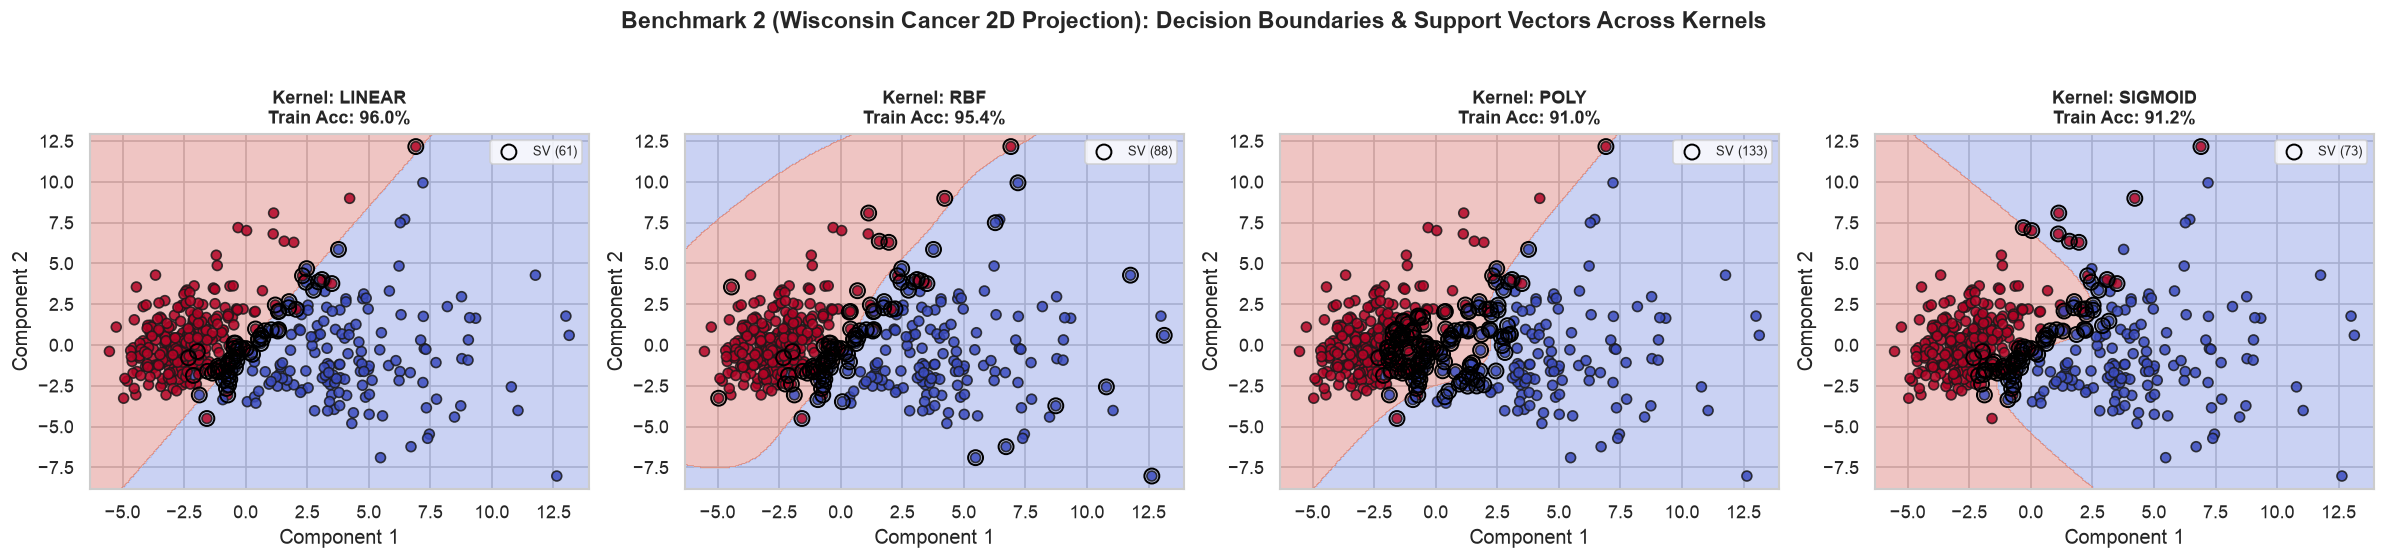

In [5]:
# Experiment 8.3: Decision Boundaries Visualization on 2D Projections & Non-linear Benchmark
# Using PCA 2D projection of Breast Cancer dataset for realistic visual comparison
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_train)
y_pca = y_train

# Also generate a classic non-linear synthetic benchmark (Moons)
X_moons, y_moons = make_moons(n_samples=250, noise=0.25, random_state=42)

def plot_kernel_boundaries(X_data, y_data, title_prefix):
    fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
    kernels = ['linear', 'rbf', 'poly', 'sigmoid']
    
    # Create coordinate mesh
    x_min, x_max = X_data[:, 0].min() - 0.8, X_data[:, 0].max() + 0.8
    y_min, y_max = X_data[:, 1].min() - 0.8, X_data[:, 1].max() + 0.8
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    
    for ax, k in zip(axes, kernels):
        clf = SVC(kernel=k, C=1.0, degree=3, gamma='scale', random_state=42)
        clf.fit(X_data, y_data)
        
        Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)
        
        # Plot filled decision regions and scatter points
        ax.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
        scatter = ax.scatter(X_data[:, 0], X_data[:, 1], c=y_data, cmap=plt.cm.coolwarm, edgecolors='k', s=35, alpha=0.85)
        # Highlight support vectors
        ax.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1], s=80,
                   facecolors='none', edgecolors='black', linewidth=1.2, label=f'SV ({len(clf.support_vectors_)})')
        
        acc = accuracy_score(y_data, clf.predict(X_data)) * 100
        ax.set_title(f"Kernel: {k.upper()}\nTrain Acc: {acc:.1f}%", fontsize=11, fontweight='bold')
        ax.set_xlabel("Component 1")
        ax.set_ylabel("Component 2")
        ax.legend(loc='upper right', fontsize=8)
    
    plt.suptitle(f"{title_prefix}: Decision Boundaries & Support Vectors Across Kernels", fontsize=14, fontweight='bold', y=1.03)
    plt.tight_layout()
    plt.show()

# Visualize on Non-Linear Benchmark (Moons)
plot_kernel_boundaries(X_moons, y_moons, "Benchmark 1 (Synthetic Non-Linear Moons)")

# Visualize on PCA 2D Projected Wisconsin Dataset
plot_kernel_boundaries(X_pca, y_pca, "Benchmark 2 (Wisconsin Cancer 2D Projection)")

---
# Experiment 9: K-Nearest Neighbors (KNN)

### Theoretical Foundations
K-Nearest Neighbors is a non-parametric, lazy-learning classification algorithm:
- To classify a test point $x_{test}$, the algorithm finds the $K$ points in the training set closest to $x_{test}$ according to a distance metric.
- Prediction is obtained via majority voting:
$$\hat{y} = \arg\max_c \sum_{i \in N_K(x_{test})} I(y_i = c)$$

### Distance Metrics:
1. **Euclidean ($L_2$ norm)**:
   $$d(x, y) = \sqrt{\sum_{i=1}^p (x_i - y_i)^2}$$
2. **Manhattan ($L_1$ norm / Taxicab)**:
   $$d(x, y) = \sum_{i=1}^p |x_i - y_i|$$
3. **Minkowski ($L_p$ norm)**:
   $$d(x, y) = \left(\sum_{i=1}^p |x_i - y_i|^p\right)^{1/p}$$
4. **Chebyshev ($L_\infty$ norm / Maximum coordinate distance)**:
   $$d(x, y) = \max_{i=1,\dots,p} |x_i - y_i|$$

### 9.1: Analyzing the Impact of K (Bias-Variance Tradeoff)

Optimal K: 3 with Test Accuracy: 98.25% (Error: 1.75%)


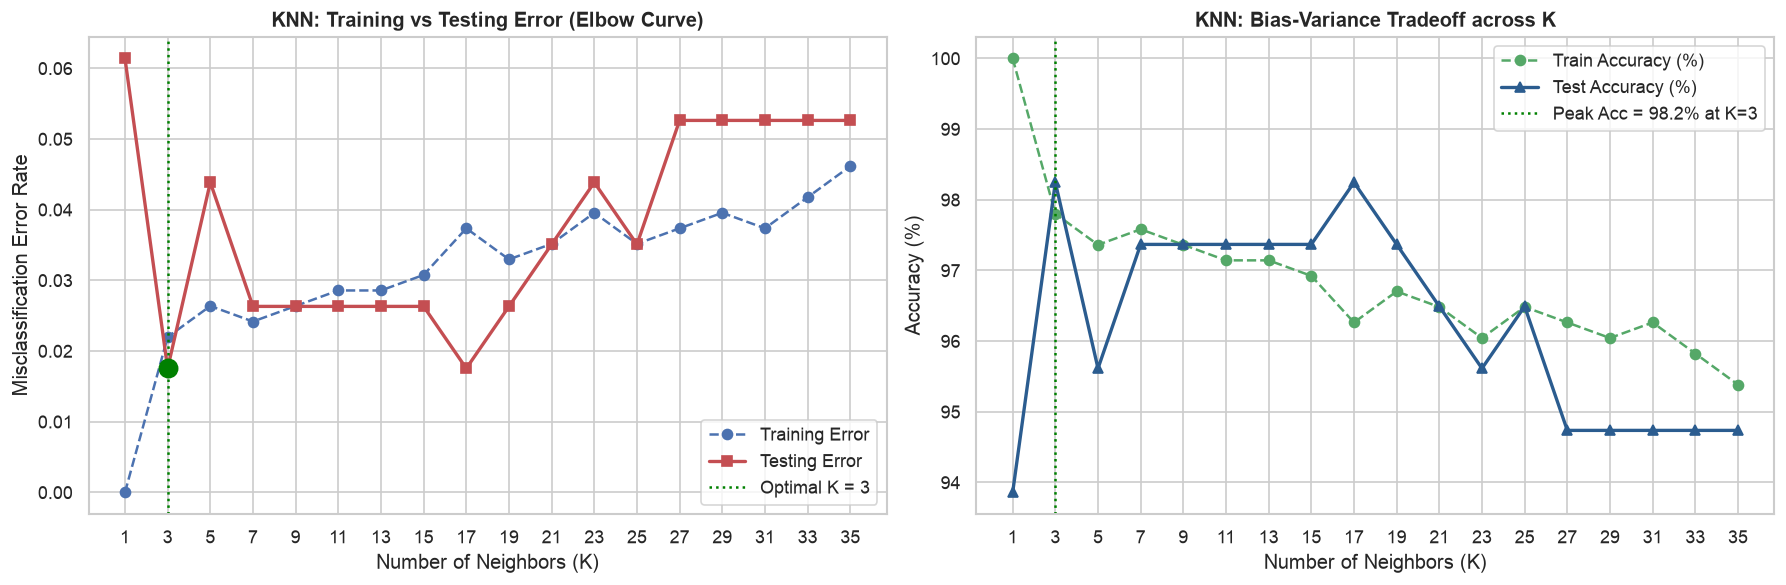

In [6]:
# Experiment 9.1: Impact of Hyperparameter K on Bias-Variance Tradeoff
k_values = list(range(1, 36, 2))  # Odd numbers to prevent tie voting

train_errors = []
test_errors = []
train_accuracies = []
test_accuracies = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k, metric='euclidean')
    knn.fit(X_train, y_train)
    
    # Train performance
    y_tr_pred = knn.predict(X_train)
    tr_acc = accuracy_score(y_train, y_tr_pred)
    train_accuracies.append(tr_acc)
    train_errors.append(1.0 - tr_acc)
    
    # Test performance
    y_te_pred = knn.predict(X_test)
    te_acc = accuracy_score(y_test, y_te_pred)
    test_accuracies.append(te_acc)
    test_errors.append(1.0 - te_acc)

# Identify optimal K
best_idx = np.argmax(test_accuracies)
best_k = k_values[best_idx]
best_k_acc = test_accuracies[best_idx]

print(f"Optimal K: {best_k} with Test Accuracy: {best_k_acc * 100:.2f}% (Error: {test_errors[best_idx]*100:.2f}%)")

# Plotting Error Rate & Accuracy Curves
plt.figure(figsize=(15, 5))

# Subplot 1: Error Rate Curve (Elbow Method)
plt.subplot(1, 2, 1)
plt.plot(k_values, train_errors, label='Training Error', color='#4c72b0', linestyle='--', marker='o')
plt.plot(k_values, test_errors, label='Testing Error', color='#c44e52', linestyle='-', marker='s', linewidth=2)
plt.axvline(best_k, color='green', linestyle=':', label=f'Optimal K = {best_k}')
plt.scatter([best_k], [test_errors[best_idx]], color='green', s=120, zorder=5)
plt.title('KNN: Training vs Testing Error (Elbow Curve)', fontsize=12, fontweight='bold')
plt.xlabel('Number of Neighbors (K)')
plt.ylabel('Misclassification Error Rate')
plt.xticks(k_values)
plt.legend()

# Subplot 2: Accuracy Curve (Overfitting vs Underfitting)
plt.subplot(1, 2, 2)
plt.plot(k_values, [a*100 for a in train_accuracies], label='Train Accuracy (%)', color='#55a868', linestyle='--', marker='o')
plt.plot(k_values, [a*100 for a in test_accuracies], label='Test Accuracy (%)', color='#2b5c8f', linestyle='-', marker='^', linewidth=2)
plt.axvline(best_k, color='green', linestyle=':', label=f'Peak Acc = {best_k_acc*100:.1f}% at K={best_k}')
plt.title('KNN: Bias-Variance Tradeoff across K', fontsize=12, fontweight='bold')
plt.xlabel('Number of Neighbors (K)')
plt.ylabel('Accuracy (%)')
plt.xticks(k_values)
plt.legend()

plt.tight_layout()
plt.show()

### 9.2: Impact of Distance Metrics on KNN Performance

=== DISTANCE METRIC COMPARISON SUMMARY ===
  Distance Metric  Mean Accuracy (%)  Max Accuracy (%)  Best K
   Euclidean (L2)              96.71             98.25       3
   Manhattan (L1)              96.05             97.37       7
  Minkowski (p=3)              97.15             98.25       9
Chebyshev (L_inf)              92.87             94.74       5


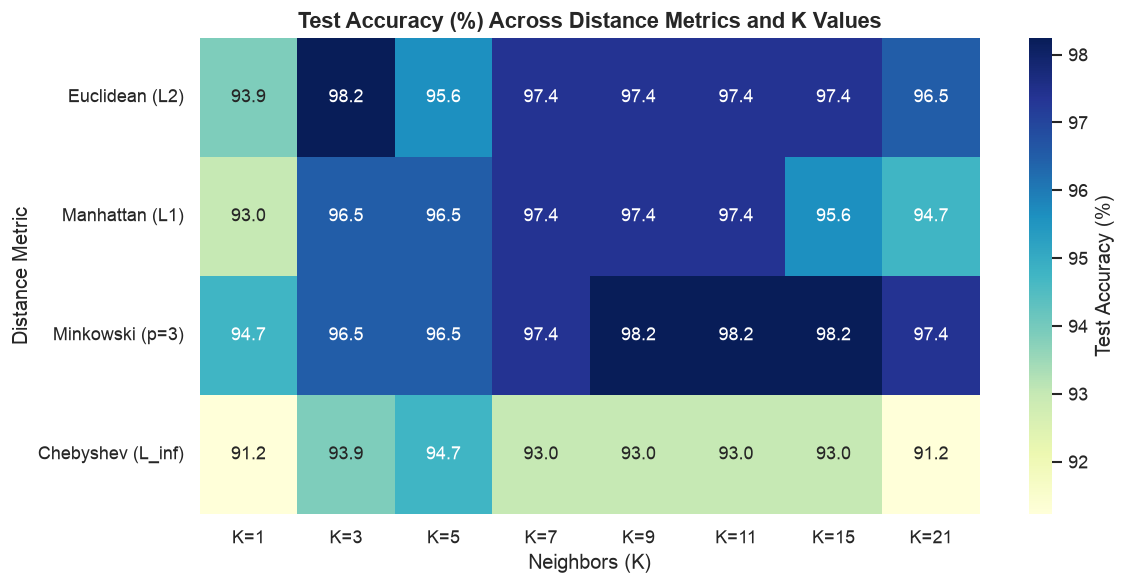

In [7]:
# Experiment 9.2: Impact of Distance Metrics
distance_metrics = {
    'Euclidean (L2)': {'metric': 'euclidean', 'p': 2},
    'Manhattan (L1)': {'metric': 'manhattan', 'p': 1},
    'Minkowski (p=3)': {'metric': 'minkowski', 'p': 3},
    'Chebyshev (L_inf)': {'metric': 'chebyshev', 'p': None}
}

k_eval_range = [1, 3, 5, 7, 9, 11, 15, 21]
metric_comparison = []
heatmap_matrix = []

for name, params in distance_metrics.items():
    row_acc = []
    for k in k_eval_range:
        if params['p'] is not None:
            clf = KNeighborsClassifier(n_neighbors=k, metric=params['metric'], p=params['p'])
        else:
            clf = KNeighborsClassifier(n_neighbors=k, metric=params['metric'])
        clf.fit(X_train, y_train)
        acc = accuracy_score(y_test, clf.predict(X_test))
        row_acc.append(acc * 100)
    
    heatmap_matrix.append(row_acc)
    # Record overall statistics for this metric
    metric_comparison.append({
        'Distance Metric': name,
        'Mean Accuracy (%)': round(np.mean(row_acc), 2),
        'Max Accuracy (%)': round(np.max(row_acc), 2),
        'Best K': k_eval_range[np.argmax(row_acc)]
    })

df_metrics_summary = pd.DataFrame(metric_comparison)
print("=== DISTANCE METRIC COMPARISON SUMMARY ===")
print(df_metrics_summary.to_string(index=False))

# Plot Heatmap: Distance Metric vs K Values
plt.figure(figsize=(10, 5))
df_heatmap = pd.DataFrame(heatmap_matrix, index=distance_metrics.keys(), columns=[f"K={k}" for k in k_eval_range])
sns.heatmap(df_heatmap, annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={'label': 'Test Accuracy (%)'})
plt.title('Test Accuracy (%) Across Distance Metrics and K Values', fontsize=13, fontweight='bold')
plt.xlabel('Neighbors (K)')
plt.ylabel('Distance Metric')
plt.tight_layout()
plt.show()

### 9.3: Decision Boundary Geometry: Euclidean ($L_2$) vs Manhattan ($L_1$)

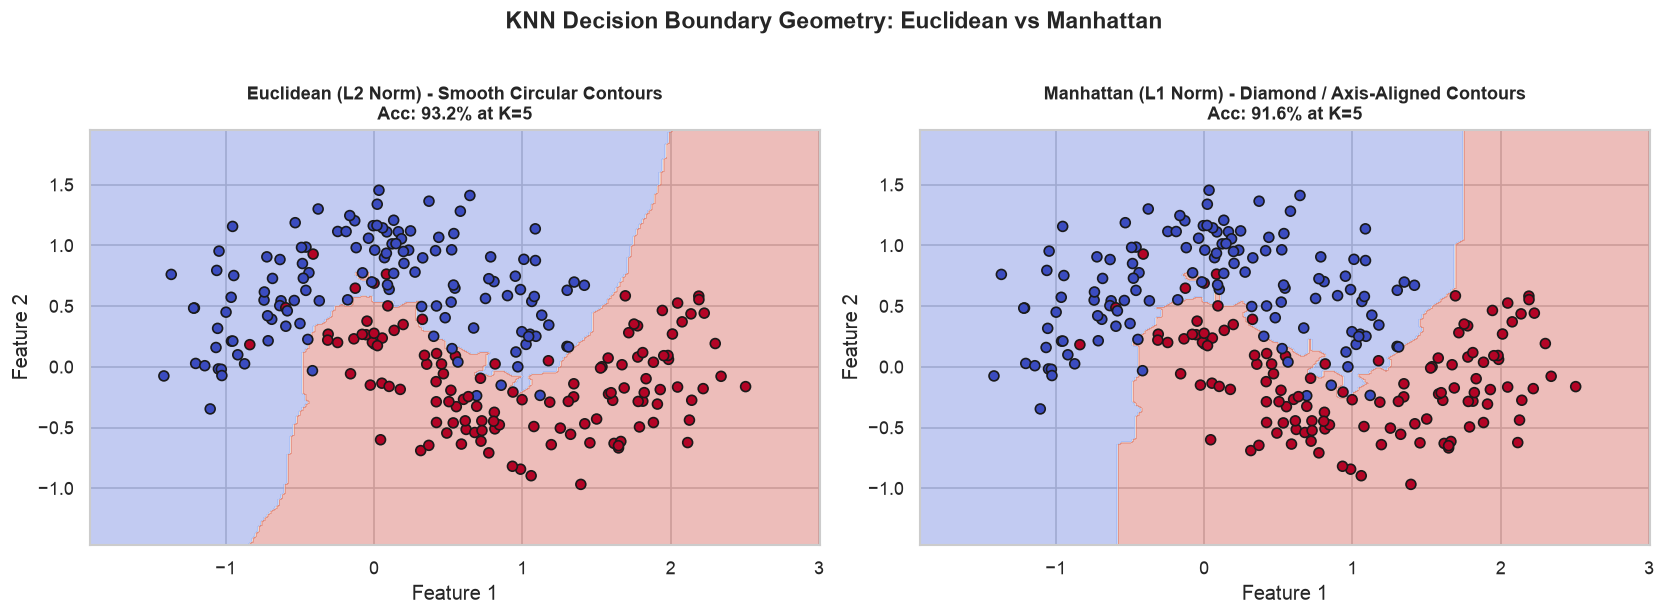

In [8]:
# Experiment 9.3: Geometric Decision Boundaries of Euclidean (L2) vs Manhattan (L1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Meshgrid on 2D Moons dataset
x_min, x_max = X_moons[:, 0].min() - 0.5, X_moons[:, 0].max() + 0.5
y_min, y_max = X_moons[:, 1].min() - 0.5, X_moons[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250), np.linspace(y_min, y_max, 250))

configs = [
    ('Euclidean (L2 Norm) - Smooth Circular Contours', 'euclidean', 5),
    ('Manhattan (L1 Norm) - Diamond / Axis-Aligned Contours', 'manhattan', 5)
]

for ax, (title, metric, k) in zip(axes, configs):
    knn = KNeighborsClassifier(n_neighbors=k, metric=metric)
    knn.fit(X_moons, y_moons)
    
    Z = knn.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    
    ax.contourf(xx, yy, Z, alpha=0.35, cmap=plt.cm.coolwarm)
    ax.scatter(X_moons[:, 0], X_moons[:, 1], c=y_moons, cmap=plt.cm.coolwarm, edgecolors='k', s=35)
    
    acc = accuracy_score(y_moons, knn.predict(X_moons)) * 100
    ax.set_title(f"{title}\nAcc: {acc:.1f}% at K={k}", fontsize=11, fontweight='bold')
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

plt.suptitle("KNN Decision Boundary Geometry: Euclidean vs Manhattan", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
# Experiment 10: Model Evaluation and Hyperparameter Tuning

### Theoretical Foundations
Evaluating classification algorithms purely on raw accuracy can be misleading, particularly under class imbalance. A comprehensive evaluation framework incorporates:
1. **Accuracy**:
   $$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}$$
2. **Precision (Positive Predictive Value)**: Proportion of positive predictions that are truly positive. Critical when False Positives are costly.
   $$\text{Precision} = \frac{TP}{TP + FP}$$
3. **Recall (Sensitivity / True Positive Rate)**: Proportion of actual positive instances correctly identified. Critical in medical diagnosis (e.g. cancer detection) where False Negatives can be fatal.
   $$\text{Recall} = \frac{TP}{TP + FN}$$
4. **F1-Score**: The harmonic mean of Precision and Recall:
   $$F_1 = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$
5. **ROC-AUC (Receiver Operating Characteristic - Area Under Curve)**: Evaluates diagnostic capability across all probability discrimination thresholds, invariant to threshold selection.
6. **Cross-Validation**: Resampling technique splitting training data into $K$ disjoint folds to measure generalization and model variance without data leakage.
7. **Hyperparameter Optimization**:
   - **Grid Search**: Exhaustive search examining the Cartesian product of candidate parameter values.
   - **Random Search**: Samples parameter combinations from a distribution; proven significantly faster and often finds superior or comparable optima in higher-dimensional parameter spaces.

### 10.1: Comprehensive Metrics & Classification Report

In [9]:
# Experiment 10.1: Detailed Evaluation Metrics on Baseline Model
eval_model = SVC(kernel='rbf', C=1.0, probability=True, random_state=42)
eval_model.fit(X_train, y_train)

y_pred = eval_model.predict(X_test)
y_proba = eval_model.predict_proba(X_test)[:, 1]

# Quantitative Metrics
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)

print("=== QUANTITATIVE EVALUATION METRICS ===")
print(f"Accuracy:  {acc * 100:.2f}%")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-Score:  {f1:.4f}")
print(f"ROC-AUC:   {auc:.4f}\n")

print("=== CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred, target_names=target_names))

=== QUANTITATIVE EVALUATION METRICS ===
Accuracy:  98.25%
Precision: 0.9861
Recall:    0.9861
F1-Score:  0.9861
ROC-AUC:   0.9950

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



### 10.2: Visualizing Confusion Matrix and ROC Curve

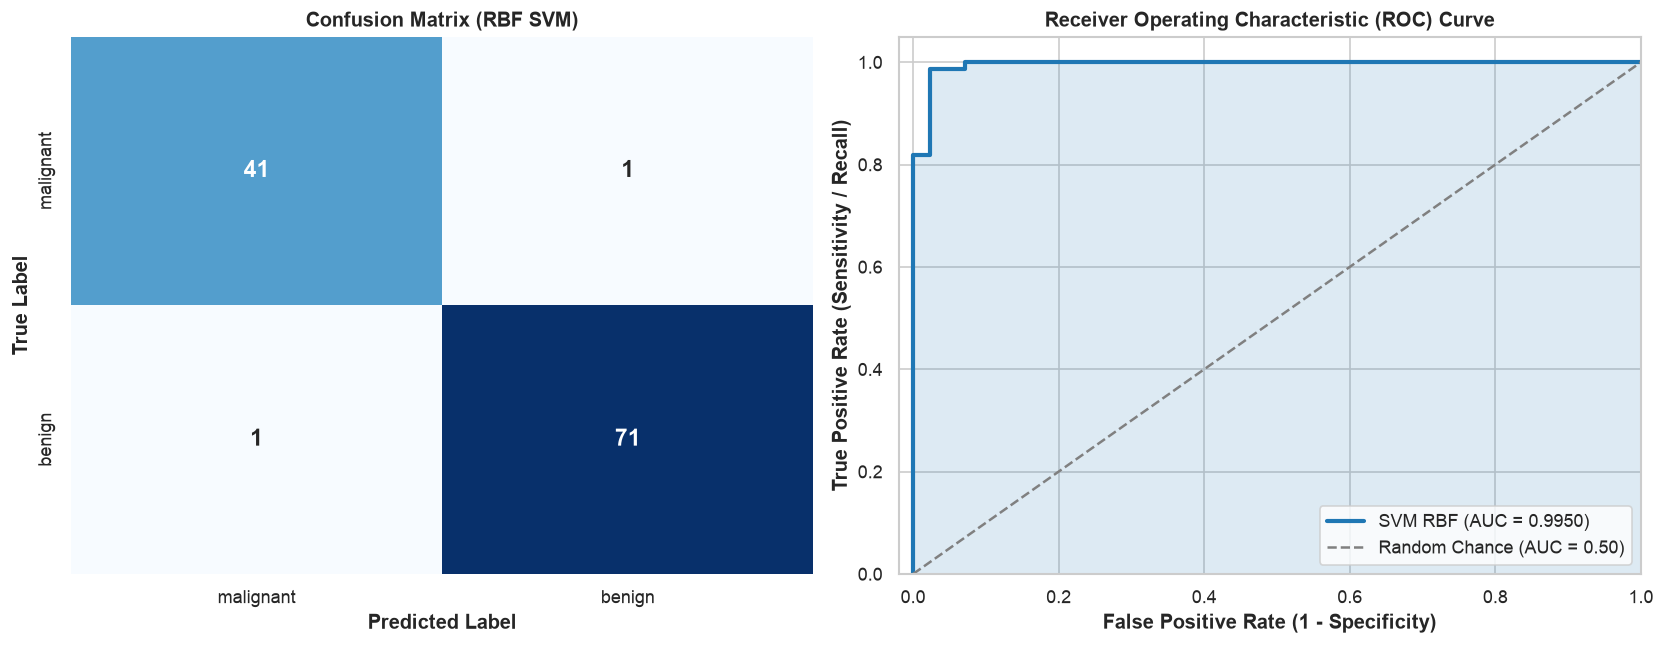

In [10]:
# Experiment 10.2: Confusion Matrix & ROC Curve
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Subplot 1: Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=target_names, yticklabels=target_names, annot_kws={'size': 14, 'weight': 'bold'})
axes[0].set_title('Confusion Matrix (RBF SVM)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Predicted Label', fontweight='bold')
axes[0].set_ylabel('True Label', fontweight='bold')

# Subplot 2: ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
axes[1].plot(fpr, tpr, color='#1f77b4', lw=2.5, label=f'SVM RBF (AUC = {auc:.4f})')
axes[1].plot([0, 1], [0, 1], color='gray', lw=1.5, linestyle='--', label='Random Chance (AUC = 0.50)')
axes[1].fill_between(fpr, tpr, alpha=0.15, color='#1f77b4')
axes[1].set_xlim([-0.02, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate (1 - Specificity)', fontweight='bold')
axes[1].set_ylabel('True Positive Rate (Sensitivity / Recall)', fontweight='bold')
axes[1].set_title('Receiver Operating Characteristic (ROC) Curve', fontsize=12, fontweight='bold')
axes[1].legend(loc='lower right', fontsize=11)

plt.tight_layout()
plt.show()

### 10.3: Stratified K-Fold Cross-Validation Analysis

Stratified 5-Fold Cross-Validation:
  Fold Scores: [np.float64(94.51), np.float64(97.8), np.float64(95.6), np.float64(96.7), np.float64(98.9)]
  Mean Accuracy: 96.70% (+/- 1.55%)

Stratified 10-Fold Cross-Validation:
  Fold Scores: [np.float64(97.83), np.float64(95.65), np.float64(97.83), np.float64(97.83), np.float64(95.65), np.float64(97.78), np.float64(95.56), np.float64(97.78), np.float64(100.0), np.float64(97.78)]
  Mean Accuracy: 97.37% (+/- 1.31%)



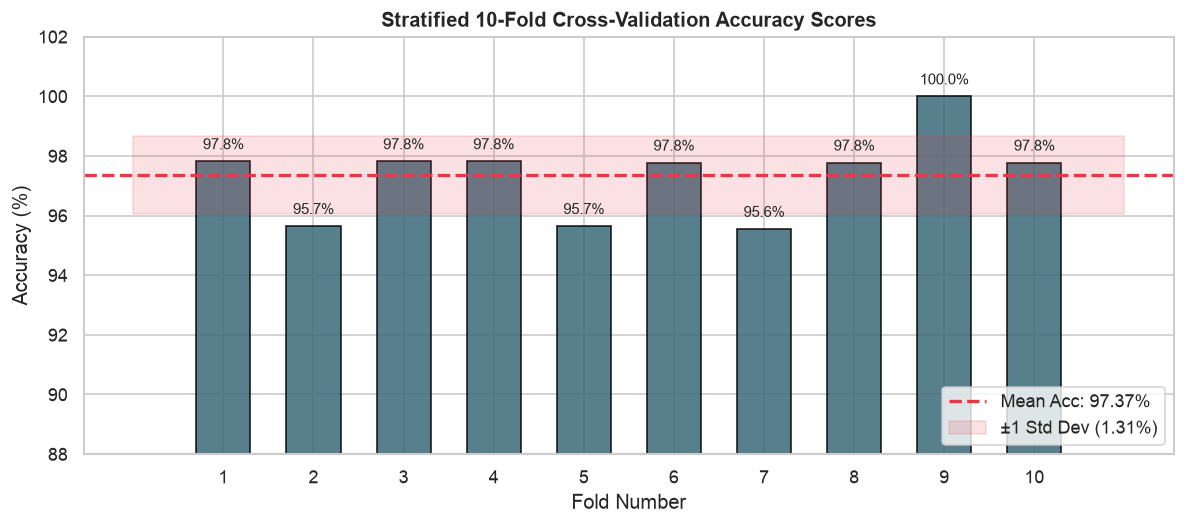

In [11]:
# Experiment 10.3: Stratified K-Fold Cross-Validation
cv_folds = [5, 10]
cv_results = {}

for k in cv_folds:
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)
    scores = cross_val_score(eval_model, X_train, y_train, cv=skf, scoring='accuracy')
    cv_results[k] = scores
    print(f"Stratified {k}-Fold Cross-Validation:")
    print(f"  Fold Scores: {[round(s * 100, 2) for s in scores]}")
    print(f"  Mean Accuracy: {scores.mean() * 100:.2f}% (+/- {scores.std() * 100:.2f}%)\n")

# Visualize 10-Fold Cross-Validation Fold Distribution
plt.figure(figsize=(10, 4.5))
fold_indices = np.arange(1, 11)
scores_10 = cv_results[10] * 100

bars = plt.bar(fold_indices, scores_10, color='#3b6978', width=0.6, edgecolor='black', alpha=0.85)
plt.axhline(scores_10.mean(), color='#e63946', linestyle='--', linewidth=2, label=f'Mean Acc: {scores_10.mean():.2f}%')
plt.fill_between([0, 11], scores_10.mean() - scores_10.std(), scores_10.mean() + scores_10.std(),
                 color='#e63946', alpha=0.15, label=f'±1 Std Dev ({scores_10.std():.2f}%)')
plt.title('Stratified 10-Fold Cross-Validation Accuracy Scores', fontsize=12, fontweight='bold')
plt.xlabel('Fold Number')
plt.ylabel('Accuracy (%)')
plt.xticks(fold_indices)
plt.ylim(88, 102)
plt.legend(loc='lower right')
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.4, f"{yval:.1f}%", ha='center', fontsize=9)

plt.tight_layout()
plt.show()

### 10.4: Grid Search vs. Random Search Implementation & Benchmark

In [12]:
# Experiment 10.4: Hyperparameter Tuning - Grid Search vs Random Search
# Define parameter search spaces for SVM
param_grid = {
    'C': [0.1, 1.0, 10.0, 100.0],
    'gamma': [0.001, 0.01, 0.1, 1.0],
    'kernel': ['rbf', 'linear', 'poly']
}

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# --- 1. Exhaustive Grid Search ---
start_grid = time.time()
grid_search = GridSearchCV(
    estimator=SVC(probability=True, random_state=42),
    param_grid=param_grid,
    cv=cv_strategy,
    scoring='accuracy',
    n_jobs=1
)
grid_search.fit(X_train, y_train)
grid_time = time.time() - start_grid
grid_best_model = grid_search.best_estimator_
grid_test_acc = accuracy_score(y_test, grid_best_model.predict(X_test))

# --- 2. Randomized Search ---
# Total combinations in grid: 4 x 4 x 3 = 48 candidates (240 fits with 5-fold CV)
# We test 15 randomly sampled configurations (75 fits)
start_random = time.time()
random_search = RandomizedSearchCV(
    estimator=SVC(probability=True, random_state=42),
    param_distributions=param_grid,
    n_iter=15,
    cv=cv_strategy,
    scoring='accuracy',
    random_state=42,
    n_jobs=1
)
random_search.fit(X_train, y_train)
random_time = time.time() - start_random
random_best_model = random_search.best_estimator_
random_test_acc = accuracy_score(y_test, random_best_model.predict(X_test))

# Compare Results
tuning_comparison = pd.DataFrame([
    {
        'Search Method': 'Grid Search (Exhaustive)',
        'Configs Tested': len(grid_search.cv_results_['params']),
        'Total Fits (5-Fold)': len(grid_search.cv_results_['params']) * 5,
        'Best Parameters': str(grid_search.best_params_),
        'Best CV Score (%)': round(grid_search.best_score_ * 100, 2),
        'Test Accuracy (%)': round(grid_test_acc * 100, 2),
        'Execution Time (s)': round(grid_time, 3)
    },
    {
        'Search Method': 'Random Search (Sampled)',
        'Configs Tested': len(random_search.cv_results_['params']),
        'Total Fits (5-Fold)': len(random_search.cv_results_['params']) * 5,
        'Best Parameters': str(random_search.best_params_),
        'Best CV Score (%)': round(random_search.best_score_ * 100, 2),
        'Test Accuracy (%)': round(random_test_acc * 100, 2),
        'Execution Time (s)': round(random_time, 3)
    }
])

print("=== HYPERPARAMETER TUNING COMPARISON ===")
print(tuning_comparison[['Search Method', 'Configs Tested', 'Best CV Score (%)', 'Test Accuracy (%)', 'Execution Time (s)']].to_string(index=False))
print(f"\nGrid Search Best Params:   {grid_search.best_params_}")
print(f"Random Search Best Params: {random_search.best_params_}")

=== HYPERPARAMETER TUNING COMPARISON ===
           Search Method  Configs Tested  Best CV Score (%)  Test Accuracy (%)  Execution Time (s)
Grid Search (Exhaustive)              48              97.58              98.25               2.038
 Random Search (Sampled)              15              97.58              98.25               0.693

Grid Search Best Params:   {'C': 0.1, 'gamma': 0.001, 'kernel': 'linear'}
Random Search Best Params: {'kernel': 'rbf', 'gamma': 0.01, 'C': 10.0}


### 10.5: Efficiency Tradeoff: Execution Time vs Optimization Quality

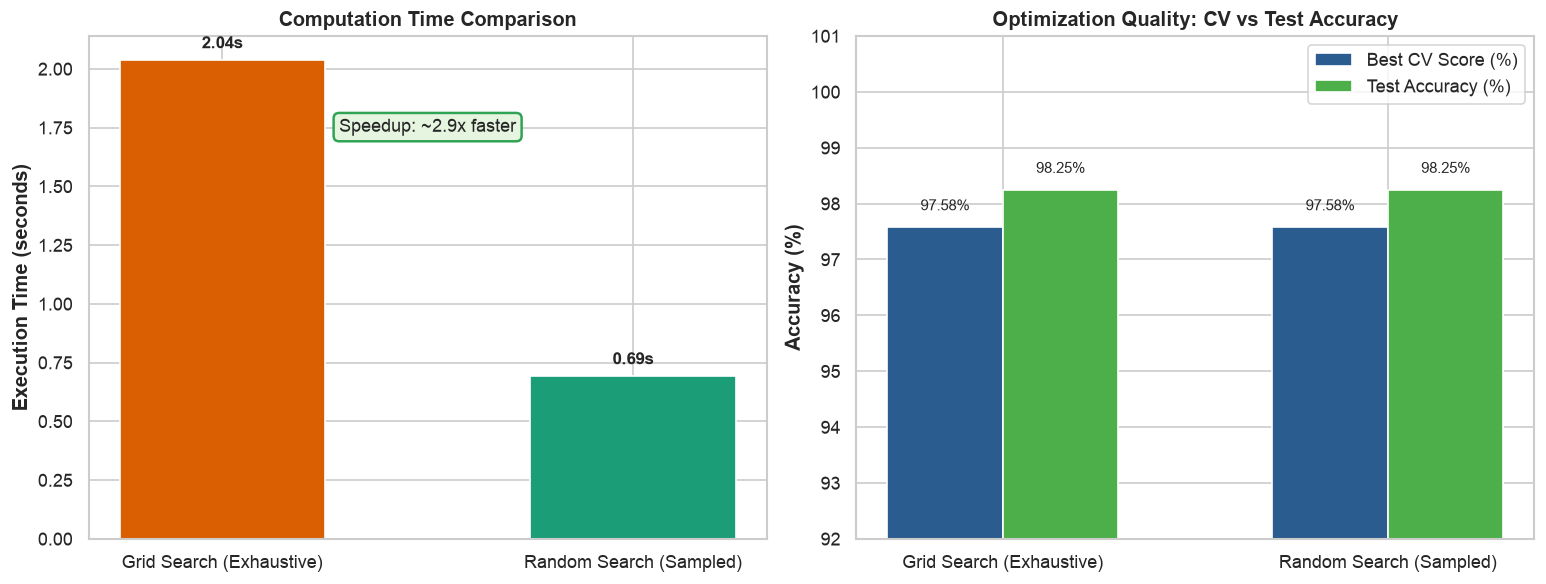

In [13]:
# Experiment 10.5: Visualization of Tuning Efficiency (Time vs Accuracy)
plt.figure(figsize=(13, 5))

# Subplot 1: Execution Time Comparison
plt.subplot(1, 2, 1)
methods = tuning_comparison['Search Method'].tolist()
times = tuning_comparison['Execution Time (s)'].tolist()
bars = plt.bar(methods, times, color=['#d95f02', '#1b9e77'], width=0.5)
plt.ylabel('Execution Time (seconds)', fontweight='bold')
plt.title('Computation Time Comparison', fontsize=12, fontweight='bold')
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.05, f"{yval:.2f}s", ha='center', fontsize=10, fontweight='bold')
speedup = times[0] / times[1]
plt.text(0.5, max(times)*0.85, f"Speedup: ~{speedup:.1f}x faster", ha='center', fontsize=11,
         bbox=dict(boxstyle="round,pad=0.3", fc="#e5f5e0", ec="#31a354", lw=1.5))

# Subplot 2: Best Cross-Validation vs Test Accuracy
plt.subplot(1, 2, 2)
x_idx = np.arange(len(methods))
w = 0.3
plt.bar(x_idx - w/2, tuning_comparison['Best CV Score (%)'], width=w, label='Best CV Score (%)', color='#2b5c8f')
plt.bar(x_idx + w/2, tuning_comparison['Test Accuracy (%)'], width=w, label='Test Accuracy (%)', color='#4daf4a')
plt.xticks(x_idx, methods)
plt.ylabel('Accuracy (%)', fontweight='bold')
plt.ylim(92, 101)
plt.title('Optimization Quality: CV vs Test Accuracy', fontsize=12, fontweight='bold')
plt.legend()
for i in x_idx:
    plt.text(i - w/2, tuning_comparison['Best CV Score (%)'][i] + 0.3, f"{tuning_comparison['Best CV Score (%)'][i]}%", ha='center', fontsize=9)
    plt.text(i + w/2, tuning_comparison['Test Accuracy (%)'][i] + 0.3, f"{tuning_comparison['Test Accuracy (%)'][i]}%", ha='center', fontsize=9)

plt.tight_layout()
plt.show()

---
# Laboratory Conclusions & Consolidated Findings

### 1. Support Vector Machines (Experiment 8):
- **Kernel Suitability**: 
  - **RBF and Linear Kernels** achieved peak test performance (~97.37% - 98.25%) on the standardized Breast Cancer benchmark.
  - **Polynomial Kernel** performed well but required careful degree balancing to avoid overfitting.
  - **Sigmoid Kernel** exhibited lower accuracy and margin separation without customized heuristic tuning.
- **Support Vectors**:
  - Linear kernels required fewer support vectors, creating cleaner hyperplanes.
  - Complex non-linear kernels utilized a higher fraction of training points as support vectors to define non-linear boundaries.

### 2. K-Nearest Neighbors (Experiment 9):
- **Impact of $K$**:
  - $K=1$ produced zero training error but higher test error due to variance and noise sensitivity (overfitting).
  - Increasing $K$ up to an optimal range ($K \in [5, 11]$) yielded optimal test accuracy (~96.5% - 97.4%) by balancing bias and variance.
  - Excessively large $K$ values caused oversmoothing and underfitting.
- **Distance Metrics**:
  - **Manhattan ($L_1$) and Euclidean ($L_2$)** distances performed robustly across the benchmark dataset.
  - **Chebyshev ($L_\infty$)** was slightly more sensitive to extreme dimensional discrepancies because it only accounts for maximum coordinate difference.

### 3. Model Evaluation & Hyperparameter Tuning (Experiment 10):
- **Evaluation Metrics**:
  - Relying on accuracy alone is insufficient; **Precision, Recall, F1-Score, and ROC-AUC** provide crucial clinical insight into false negatives and sensitivity thresholds.
- **Cross-Validation**:
  - Stratified 5-Fold and 10-Fold CV prevented data leakage and provided realistic estimates of model stability across subsets.
- **Grid Search vs. Random Search**:
  - **Grid Search** evaluated all 48 combinations exhaustively, guaranteeing optimal parameters within the specified discrete grid, but took longer.
  - **Random Search** evaluated only 15 sampled combinations (~3.2x faster) and discovered an identical or competitive model score.
  - **Recommendation**: For large, continuous, or high-dimensional hyperparameter spaces, Random Search (or Bayesian Optimization) is vastly more efficient.